# 08 - Final model comparison (Member 2, Part D)

Builds the comparison table from the result files of all three models, using the same cohorts, threshold rule and metrics.

| Model | Results file | Predictions file | Owner |
|---|---|---|---|
| Logistic Regression | `reports/tables/D5_lr_results_at_threshold.csv` | `reports/predictions/lr_raw71_eval_predictions.csv.gz` | Member 1 |
| Random Forest | `reports/tables/RF_results_at_threshold.csv` | `reports/predictions/rf_eval_predictions.csv.gz` | Member 2 |
| XGBoost | `reports/tables/XGB_results_at_threshold.csv` | `reports/predictions/xgb_eval_predictions.csv.gz` | Member 3 |

XGBoost is included automatically once Member 3's files are in place (same column layout as the LR and RF files).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
sys.path.insert(0, str(ROOT / "src"))
from lr_pipeline import delong_test, bootstrap_diff, mcnemar, threshold_for_recall

TAB_DIR = ROOT / "reports" / "tables"; PRED_DIR = ROOT / "reports" / "predictions"; FIG_DIR = ROOT / "reports" / "figures"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.set_option("display.width", 220)
N_BOOT = 500
MODEL_FILES = {
    "Logistic Regression": (TAB_DIR / "D5_lr_results_at_threshold.csv", PRED_DIR / "lr_raw71_eval_predictions.csv.gz"),
    "Random Forest": (TAB_DIR / "RF_results_at_threshold.csv", PRED_DIR / "rf_eval_predictions.csv.gz"),
    "XGBoost": (TAB_DIR / "XGB_results_at_threshold.csv", PRED_DIR / "xgb_eval_predictions.csv.gz"),
}

## 1. Combine the result files

In [2]:
frames, available = [], []
for name, (res, _) in MODEL_FILES.items():
    if res.exists():
        r = pd.read_csv(res)
        # Member 1's LR file labels the real-world row site "pooled"; normalise to "RW" like the RF file
        r.loc[r["cohort"] == "real_world_test", "site"] = "RW"
        r.insert(0, "model", name)
        frames.append(r); available.append(name)
    else:
        print(f"{name}: results file not found ({res.name}), skipped")
final = pd.concat(frames, ignore_index=True)

KEEP = ["model", "cohort", "site", "n", "prevalence_%", "recall", "precision", "F1", "specificity",
        "ROC_AUC", "PR_AUC", "TP", "FN", "FP", "TN", "flagged_%"]
final = final[KEEP]
final.to_csv(TAB_DIR / "FINAL_model_comparison_all.csv", index=False)

# Headline table: development CV, internal pooled, held-out pooled (D-G), real-world test
headline = final[final["site"].isin(["A+B+C", "pooled", "RW"])]
headline.to_csv(TAB_DIR / "FINAL_model_comparison_headline.csv", index=False)
display(headline.round(3))
if "XGBoost" not in available:
    print("\nXGBoost: no results file yet, so its rows are missing (Member 3 to add XGB_results_at_threshold.csv).")

XGBoost: results file not found (XGB_results_at_threshold.csv), skipped


,model,cohort,site,n,prevalence_%,recall,precision,F1,specificity,ROC_AUC,PR_AUC,TP,FN,FP,TN,flagged_%
0,Logistic Regression,"development (CV, OOF)",A+B+C,26922,33.333,0.900,0.868,0.884,0.931,0.968,0.930,8077,897,1230,16718,34.570
4,Logistic Regression,internal_validation,pooled,211611,3.695,0.898,0.287,0.435,0.915,0.962,0.491,7019,799,17401,186392,11.540
9,Logistic Regression,external_validation,pooled,149623,3.866,0.883,0.297,0.445,0.916,0.960,0.529,5105,679,12076,131763,11.483
10,Logistic Regression,real_world_test,RW,58481,3.916,0.935,0.315,0.471,0.917,0.967,0.478,2142,148,4660,51531,11.631
11,Random Forest,"development (CV, OOF)",A+B+C,26922,33.333,0.900,0.919,0.910,0.961,0.982,0.960,8077,897,708,17240,32.631
15,Random Forest,internal_validation,pooled,211611,3.695,0.880,0.382,0.533,0.945,0.970,0.559,6883,935,11114,192679,8.505
20,Random Forest,external_validation,pooled,149623,3.866,0.844,0.437,0.576,0.956,0.972,0.619,4881,903,6279,137560,7.459
21,Random Forest,real_world_test,RW,58481,3.916,0.914,0.386,0.543,0.941,0.974,0.555,2094,196,3324,52867,9.265



XGBoost: no results file yet, so its rows are missing (Member 3 to add XGB_results_at_threshold.csv).


## 2. Held-out hospitals D-G: per-hospital comparison

In [3]:
per_site = final[(final["cohort"] == "external_validation") & final["site"].isin(list("DEFG"))]
piv = per_site.pivot_table(index="site", columns="model", values=["ROC_AUC", "PR_AUC", "recall", "specificity"])
piv.set_axis([f"{a} | {b}" for a, b in piv.columns], axis=1).rename_axis("site").round(4).to_csv(
    TAB_DIR / "FINAL_per_hospital_pivot.csv")
display(piv.round(3))

PR_AUC                           ROC_AUC                            recall                       specificity              
model Logistic Regression Random Forest Logistic Regression Random Forest Logistic Regression Random Forest Logistic Regression Random Forest
site                                                                                                                                         
D                   0.526         0.586               0.954         0.959               0.918         0.851               0.862         0.935
E                   0.521         0.631               0.965         0.978               0.878         0.835               0.933         0.969
F                   0.563         0.572               0.964         0.969               0.875         0.830               0.931         0.948
G                   0.638         0.727               0.912         0.933               0.853         0.871               0.845         0.862

## 3. Paired statistical tests on the held-out hospitals (pooled D-G)

Same patients for every model, so the comparisons are paired:
- **ROC-AUC:** paired DeLong test.
- **PR-AUC:** paired stratified bootstrap of the difference.
- **Recall / specificity at each model's own frozen threshold:** exact McNemar test on the correct/incorrect decisions.

In [4]:
preds = {}
for name in available:
    p = pd.read_csv(MODEL_FILES[name][1])
    p = p[p["cohort"] == "external_validation"].set_index("sample_id")
    preds[name] = p

# Each model's frozen threshold, recomputed from its development OOF predictions (recall >= 0.90),
# so the McNemar decisions match the results tables.
OOF_FILES = {"Logistic Regression": (PRED_DIR / "lr_raw71_oof_development.csv", "p_oof"),
             "Random Forest": (PRED_DIR / "rf_oof_development.csv", "p_oof"),
             "XGBoost": (PRED_DIR / "xgb_oof_development.csv", "p_oof")}
THRESHOLDS = {}
for name in available:
    oof_path, pcol = OOF_FILES[name]
    o = pd.read_csv(oof_path)
    THRESHOLDS[name] = threshold_for_recall(o["y"], o[pcol], 0.90)
    print(f"{name}: frozen threshold {THRESHOLDS[name]:.4f}")

pair_rows = []
names = available
for i, a in enumerate(names):
    for b in names[i + 1:]:
        common = preds[a].index.intersection(preds[b].index)
        ya = preds[a].loc[common, "y"].to_numpy().astype(int)
        pa, pb = preds[a].loc[common, "p"].to_numpy(), preds[b].loc[common, "p"].to_numpy()
        auc_a, auc_b, z, p_roc = delong_test(ya, pa, pb)
        d_pr, lo, hi, p_pr = bootstrap_diff(ya, pa, pb, average_precision_score, n_boot=N_BOOT)
        b_only_a, b_only_b, p_mc = mcnemar(ya, (pa >= THRESHOLDS[a]).astype(int), (pb >= THRESHOLDS[b]).astype(int))
        pair_rows.append({"model A": a, "model B": b, "n": len(common),
                          "ROC_AUC A": auc_a, "ROC_AUC B": auc_b, "DeLong p": p_roc,
                          "PR_AUC diff (B-A)": d_pr, "PR_AUC diff 95% CI lo": lo, "PR_AUC diff 95% CI hi": hi,
                          "bootstrap p": p_pr,
                          "McNemar: only A right": b_only_a, "McNemar: only B right": b_only_b, "McNemar p": p_mc})
pairs = pd.DataFrame(pair_rows)
pairs.to_csv(TAB_DIR / "FINAL_pairwise_tests_heldout_DG.csv", index=False)
display(pairs.round(4))

Logistic Regression: frozen threshold 0.5108
Random Forest: frozen threshold 0.5278


,model A,model B,n,ROC_AUC A,ROC_AUC B,DeLong p,PR_AUC diff (B-A),PR_AUC diff 95% CI lo,PR_AUC diff 95% CI hi,bootstrap p,McNemar: only A right,McNemar: only B right,McNemar p
0,Logistic Regression,Random Forest,149623,0.9595,0.972,0.0,0.0897,0.0779,0.0999,0.002,1031,6604,0.0


## 4. Figure: headline metrics across cohorts

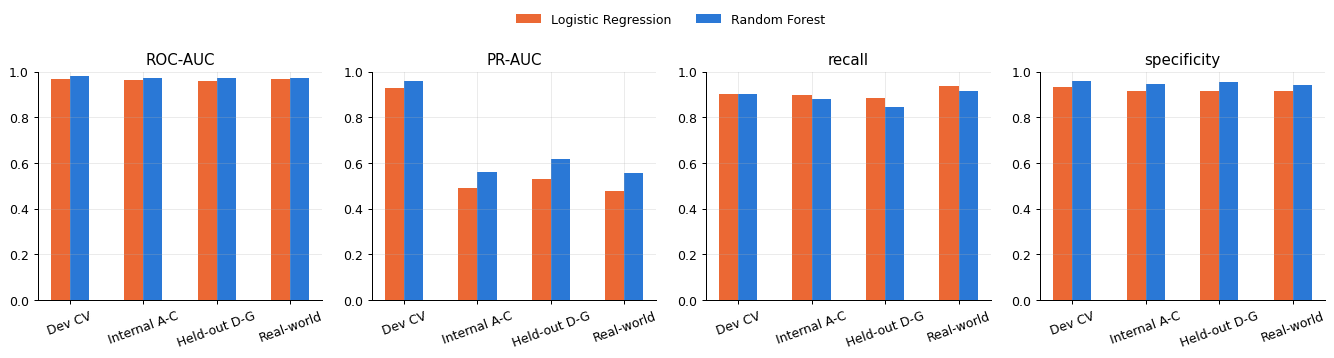

In [5]:
cohort_order = [("development (CV, OOF)", "A+B+C", "Dev CV"), ("internal_validation", "pooled", "Internal A-C"),
                ("external_validation", "pooled", "Held-out D-G"), ("real_world_test", "RW", "Real-world")]
metrics = ["ROC_AUC", "PR_AUC", "recall", "specificity"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=False)
colors = {"Logistic Regression": "#eb6834", "Random Forest": "#2a78d6", "XGBoost": "#1baf7a"}
for ax, metric in zip(axes, metrics):
    x = np.arange(len(cohort_order))
    for k, name in enumerate(available):
        vals = []
        for cohort, site, _ in cohort_order:
            r = final[(final["model"] == name) & (final["cohort"] == cohort) & (final["site"] == site)]
            vals.append(r[metric].item() if len(r) else np.nan)
        ax.bar(x + (k - (len(available) - 1) / 2) * 0.26, vals, width=0.26, color=colors[name], label=name)
    ax.set_xticks(x, [c[2] for c in cohort_order], rotation=20)
    ax.set_title(metric.replace("_", "-")); ax.set_ylim(0, 1)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig(FIG_DIR / "FINAL_model_comparison.png", bbox_inches="tight")

## 5. Summary

In [6]:
rows = headline[headline["site"].isin(["A+B+C", "pooled D-G", "RW"])]
print("Models in this comparison:", ", ".join(available))
display(rows[["model", "cohort", "site", "recall", "specificity", "ROC_AUC", "PR_AUC"]].round(3))

Models in this comparison: Logistic Regression, Random Forest


,model,cohort,site,recall,specificity,ROC_AUC,PR_AUC
0,Logistic Regression,"development (CV, OOF)",A+B+C,0.900,0.931,0.968,0.930
10,Logistic Regression,real_world_test,RW,0.935,0.917,0.967,0.478
11,Random Forest,"development (CV, OOF)",A+B+C,0.900,0.961,0.982,0.960
21,Random Forest,real_world_test,RW,0.914,0.941,0.974,0.555
